# 이야기담 — 손그림 움직이기 (15-joint RTMPose → GIF)
**런타임: GPU.** 위에서부터 순서대로 실행.

- 1번: Drive 마운트 + mmpose 환경 복원 (이미 있으면 빠르게 지나감)
- 2번: 애니메이션 스크립트 생성
- 3번: 모델 없이 데모 GIF (스크립트 확인용)
- 4번: test set 랜덤 그림 움직이기 (원본 학습 세션의 `/content/test_coco.json` 필요)
- 5번: 내 그림 업로드해서 움직이기

## 1. Drive + 환경 복원

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"

# 학습 때 쓴 dataset_info / config를 Drive(deploy)에서 복원
D = '/content/drive/MyDrive/yiyagidam/deploy'
!cp {D}/drawing15.py /content/mmpose/configs/_base_/datasets/drawing15.py
!cp {D}/drawing15_full.py /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py
!ls -la {D}
!MPLBACKEND=Agg {E} python -c "import torch, mmpose; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available())"

Mounted at /content/drive
/content
accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: ...working... done
Channels:
 - defaults
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/mmpose_env

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    libnsl-2.0.0               |       h5eee18b_0          31 KB
    packaging-26.3             |  py310h06a4308_0         329 KB
    pip-26.2.1                 |     pyhc872135_0         1.1 MB
    python-3.10.22             |       hd9cb797_0        24.4 MB
    setuptools-84.0.0          |  py310h06a4308_0         968 KB
    tk-8.6.15                  |       h54e0aa7_0         3.4 M

## 2. 애니메이션 스크립트 생성

In [ ]:
%%writefile /content/animate_drawing.py
"""손그림 + 15-joint 예측 -> 움직이는 GIF.

사용 (Colab, mmpose_env 안에서):
  # 1) test set에서 랜덤 6장 (GT bbox 사용)
  python animate_drawing.py --from-test 6
  # 2) 내가 올린 그림 (bbox 생략 = 이미지 전체)
  python animate_drawing.py --src /content/test_imgs
  # 3) 모델 없이 합성 막대인간 데모
  python animate_drawing.py --demo
"""
import os, sys, glob, json, argparse, random
os.environ.setdefault('MPLBACKEND', 'Agg')
import numpy as np, cv2
from PIL import Image

D = '/content/drive/MyDrive/yiyagidam/deploy'
CFG = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py'
CKPT = f'{D}/rtmpose-m_drawing15_ep30.pth'

# 0 nose 1 neck 2 r_sho 3 r_elb 4 r_wri 5 l_sho 6 l_elb 7 l_wri 8 pelvis
# 9 r_hip 10 r_knee 11 r_ankle 12 l_hip 13 l_knee 14 l_ankle
PARENT = {1: 8, 0: 1, 2: 1, 3: 2, 4: 3, 5: 1, 6: 5, 7: 6,
          9: 8, 10: 9, 11: 10, 12: 8, 13: 12, 14: 13}
ORDER = [8, 1, 0, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14]   # 부모가 항상 먼저
BONES = [(p, c) for c, p in PARENT.items()]
TIPS = {0, 4, 7, 11, 14}      # 끝마디(머리/손/발)는 가중치 계산 때 조금 연장
SKEL = [(0, 1), (1, 2), (2, 3), (3, 4), (1, 5), (5, 6), (6, 7), (1, 8),
        (8, 9), (9, 10), (10, 11), (8, 12), (12, 13), (13, 14)]


# ---------------------------------------------------------------- motions
def _rot(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s], [s, c]])


def _toward(rest, a, b, vec=(0.0, -1.0)):
    """a->b 뼈대를 vec 방향으로 돌리기 위한 부호있는 각도(rad). 기본은 위쪽."""
    d = rest[b] - rest[a]
    ang = np.arctan2(d[1], d[0])           # 화면 좌표(y 아래)
    tgt = np.arctan2(vec[1], vec[0])
    return (tgt - ang + np.pi) % (2 * np.pi) - np.pi


def _to_up(rest, a, b):
    return _toward(rest, a, b)


def _out(rest, hip):
    """골반 기준 바깥(좌/우) 방향 부호."""
    return 1.0 if rest[hip][0] >= rest[8][0] else -1.0


def motion(name, t, rest):
    """t in [0,1) (한 사이클). 관절별 회전(rad) dict와 루트 이동(px) 반환."""
    th = {j: 0.0 for j in range(15)}
    tr = np.zeros(2)
    S = np.ptp(rest[:, 1]) + 1e-6          # 몸 높이
    w = 2 * np.pi * t
    deg = np.deg2rad
    if name == 'wave':                      # 오른팔 들고 흔들기 + 살짝 흔들
        th[2] = 0.85 * _to_up(rest, 2, 3)
        th[3] = deg(32) * np.sin(2 * w)
        th[1] = deg(3) * np.sin(w)
    elif name == 'dance':                   # 양팔 들썩 + 몸 바운스 + 다리 번갈아
        tr[1] = -0.04 * S * abs(np.sin(w))
        th[8] = deg(5) * np.sin(w)
        th[2] = 0.55 * _to_up(rest, 2, 3) * (0.5 + 0.5 * np.sin(w))
        th[5] = 0.55 * _to_up(rest, 5, 6) * (0.5 + 0.5 * np.sin(w + np.pi))
        th[3] = deg(20) * np.sin(2 * w); th[6] = deg(-20) * np.sin(2 * w)
        th[9] = deg(14) * np.sin(w);   th[12] = deg(-14) * np.sin(w)
        th[0 + 1] = deg(-6) * np.sin(w)
    elif name == 'walk':                    # 제자리 걷기: 팔다리 교차 스윙
        tr[1] = -0.015 * S * abs(np.sin(2 * w))
        a = deg(24) * np.sin(w)
        th[9], th[12] = a, -a
        th[10], th[13] = deg(18) * max(0, np.sin(w + 1.2)), deg(18) * max(0, -np.sin(w + 1.2))
        th[2], th[5] = -deg(22) * np.sin(w), deg(22) * np.sin(w)
    elif name == 'cheer':                   # 만세 + 손 흔들기 + 가벼운 바운스
        h = abs(np.sin(w))
        tr[1] = -0.03 * S * h
        th[2] = 0.9 * _to_up(rest, 2, 3); th[5] = 0.9 * _to_up(rest, 5, 6)
        th[3] = deg(18) * np.sin(2 * w); th[6] = -deg(18) * np.sin(2 * w)
    elif name == 'jump':                    # 점프: 몸 위로 + 팔 위로 + 다리 벌리기
        h = max(0.0, np.sin(w))
        tr[1] = -0.18 * S * h
        th[2] = 0.8 * _to_up(rest, 2, 3) * h; th[5] = 0.8 * _to_up(rest, 5, 6) * h
        th[9] = 0.35 * _toward(rest, 9, 10, (_out(rest, 9), 0.6)) * h
        th[12] = 0.35 * _toward(rest, 12, 13, (_out(rest, 12), 0.6)) * h
    elif name == 'kick':                    # 오른발 차기 (오른쪽 다리가 옆으로)
        h = max(0.0, np.sin(w))
        th[9] = 0.75 * _toward(rest, 9, 10, (_out(rest, 9), -0.1)) * h
        th[10] = 0.0
        th[2] = 0.5 * _toward(rest, 2, 3, (-_out(rest, 9), 0.0)) * h
        th[8] = deg(-6) * h * _out(rest, 9)
    elif name == 'squat':                   # 스쿼트: 몸 내려가며 다리 벌어짐, 팔 앞으로
        q = 0.5 - 0.5 * np.cos(w)
        tr[1] = 0.07 * S * q
        th[9] = 0.45 * _toward(rest, 9, 10, (_out(rest, 9), 0.5)) * q
        th[12] = 0.45 * _toward(rest, 12, 13, (_out(rest, 12), 0.5)) * q
        th[2] = 0.5 * _toward(rest, 2, 3, (_out(rest, 2), 0.0)) * q
        th[5] = 0.5 * _toward(rest, 5, 6, (_out(rest, 5), 0.0)) * q
    else:
        raise ValueError(name)
    return th, tr


def pose(rest, th, tr):
    """FK: 관절 회전 -> 뼈대별 (회전, 현재 부모위치)와 새 관절 좌표."""
    pos = rest.copy().astype(np.float64)
    cum = {}
    pos[8] = rest[8] + tr
    cum[8] = th[8]
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cum[p]) @ (rest[j] - rest[p])
        cum[j] = cum[p] + th[j]
    cb = {(PARENT[c], c): cum[PARENT[c]] for c in PARENT}      # 뼈대별 회전
    return pos, cb


def _wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def retarget(rest, kt, amount):
    """다른 그림의 관절 kt 자세를 따라가는 뼈대별 회전(rest->target, amount 0~1)."""
    cb = {}
    for c, p in PARENT.items():
        dr, dt = rest[c] - rest[p], kt[c] - kt[p]
        cb[(p, c)] = amount * _wrap(np.arctan2(dt[1], dt[0]) - np.arctan2(dr[1], dr[0]))
    return cb


def pose_from_bones(rest, cb, tr=np.zeros(2)):
    pos = rest.copy().astype(np.float64)
    pos[8] = rest[8] + tr
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cb[(p, j)]) @ (rest[j] - rest[p])
    return pos


# ---------------------------------------------------------------- warp
def seg_dist(P, a, b):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab + 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)


def extend(a, b, f=0.3):
    return b + (b - a) * f


def bind(crop, rest, S, up=2):
    """잉크 픽셀을 up배 확대해 뽑고, 휴식자세 기준 뼈대 가중치를 한 번만 계산."""
    big = cv2.resize(crop, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    g = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY).astype(np.int16)
    bgc = np.median(big.reshape(-1, 3)[::97], axis=0)
    bgg = int(np.median(g[::7, ::7]))
    ys, xs = np.nonzero(g < bgg - 30)
    P = np.stack([xs, ys], 1).astype(np.float64) / up        # crop 좌표계
    col = big[ys, xs]
    eps = (0.02 * S) ** 2
    Wt = np.zeros((len(P), len(BONES)))
    for k, (p, c) in enumerate(BONES):
        b = extend(rest[p], rest[c]) if c in TIPS else rest[c]
        Wt[:, k] = 1.0 / (seg_dist(P, rest[p], b) ** 2 + eps) ** 3
    Wt /= Wt.sum(1, keepdims=True)
    return dict(P=P, col=col, W=Wt, bg=tuple(int(v) for v in bgc), up=up, shape=big.shape)


def render(B, rest, pos, cum):
    up = B['up']; H, Wd = B['shape'][:2]
    new = np.zeros_like(B['P'])
    for k, (p, c) in enumerate(BONES):
        R = _rot(cum[(p, c)])
        new += B['W'][:, k:k + 1] * (pos[p] + (B['P'] - rest[p]) @ R.T)
    ix = np.round(new[:, 0] * up).astype(int); iy = np.round(new[:, 1] * up).astype(int)
    ok = (ix >= 0) & (ix < Wd) & (iy >= 0) & (iy < H)
    canvas = np.empty((H, Wd, 3), np.uint8); canvas[:] = B['bg']
    canvas[iy[ok], ix[ok]] = B['col'][ok]
    canvas = cv2.erode(canvas, np.ones((2, 2), np.uint8))        # 늘어난 틈 메우기
    return cv2.resize(canvas, (Wd // up, H // up), interpolation=cv2.INTER_AREA)


def prep(img, kp, bbox, out=512, pad=0.35):
    """bbox 주변을 잘라 long side=out 으로 맞추고 kp도 같이 변환."""
    H, W = img.shape[:2]
    x1, y1, x2, y2 = bbox
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    s = max(x2 - x1, y2 - y1) * (1 + pad * 2)
    bg = tuple(int(v) for v in np.median(img.reshape(-1, 3)[::97], axis=0))
    M = np.array([[out / s, 0, out / 2 - cx * out / s], [0, out / s, out / 2 - cy * out / s]], np.float32)
    crop = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_AREA, borderMode=cv2.BORDER_CONSTANT, borderValue=bg)
    kp2 = kp @ M[:, :2].T + M[:, 2]
    return crop, kp2, out * (np.ptp(kp2[:, 1]) + np.ptp(kp2[:, 0])) / 2 / out


def make_gif(img, kp, bbox, path, motions=('wave', 'dance', 'walk'), n=36, fps=25, out=512, targets=()):
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    frames = []
    for m in motions:
        for i in range(n):
            th, tr = motion(m, i / n, rest)
            pos, cum = pose(rest, th, tr)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cum), cv2.COLOR_BGR2RGB)))
    for kt in targets:                       # 다른 그림의 자세로 갔다가 돌아오기
        kt = _fit(np.asarray(kt, np.float64), rest)
        for i in range(n):
            a = 0.5 - 0.5 * np.cos(2 * np.pi * i / n)
            a = min(1.0, a * 1.15)
            cb = retarget(rest, kt, a)
            pos = pose_from_bones(rest, cb)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def overlay(img, kp, thr_pts=None):
    v = img.copy()
    for a, b in SKEL:
        cv2.line(v, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (0, 128, 255), 2)
    for x, y in kp:
        cv2.circle(v, (int(x), int(y)), 3, (0, 0, 255), -1)
    return v


def _fit(kt, rest):
    """자세만 쓰므로 위치/크기 무시(방향만 사용). 형태 그대로 반환."""
    return kt



def smooth_seq(seq, k=5):
    """프레임 방향 이동평균으로 떨림 제거. seq: (T,15,2)"""
    if k <= 1 or len(seq) < k:
        return seq
    pad = k // 2
    p = np.concatenate([np.repeat(seq[:1], pad, 0), seq, np.repeat(seq[-1:], pad, 0)])
    return np.stack([p[i:i + len(seq)] for i in range(k)]).mean(0)


def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True):
    """seq(T,15,2): 영상/모캡에서 얻은 관절 시퀀스를 그림에 입힌다 (뼈대 방향 retarget)."""
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    seq = np.asarray(seq, np.float64).copy()
    if mirror:
        seq[:, :, 0] *= -1
        sw = [0, 1, 5, 6, 7, 2, 3, 4, 8, 12, 13, 14, 9, 10, 11]      # 좌우 관절 교환
        seq = seq[:, sw]
    body = max(np.ptp(seq[0, :, 1]), 1.0)
    frames = []
    for t in range(len(seq)):
        cb = retarget(rest, seq[t], 1.0)
        tr = (seq[t, 8] - seq[0, 8]) * (np.ptp(rest[:, 1]) / body) if follow_root else np.zeros(2)
        pos = pose_from_bones(rest, cb, tr)
        frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def c17to15(k):
    m = lambda a, b: (k[a] + k[b]) / 2
    return np.stack([k[0], m(5, 6), k[6], k[8], k[10], k[5], k[7], k[9], m(11, 12),
                     k[12], k[14], k[16], k[11], k[13], k[15]])


def extract_seq(video, max_frames=150, stride=None):
    """영상 -> (T,15,2) 관절 시퀀스. COCO-17 사전학습 RTMPose + 이전 프레임 기반 bbox 추적."""
    from mmpose.apis import init_model, inference_topdown
    cfg = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/rtmpose-m_8xb256-420e_coco-256x192.py'
    ck = '/content/rtmpose-m_coco-256x192.pth'
    model = init_model(cfg, ck, device='cuda:0')
    cap = cv2.VideoCapture(video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    stride = stride or max(1, int(round(n / max_frames)))
    seq, bb, i = [], None, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if i % stride == 0:
            h, w = fr.shape[:2]
            box = bb if bb is not None else np.array([0, 0, w, h], np.float32)
            r = inference_topdown(model, fr, bboxes=box[None], bbox_format='xyxy')
            k = r[0].pred_instances.keypoints[0]
            seq.append(c17to15(k))
            x1, y1 = k.min(0); x2, y2 = k.max(0)
            cx, cy, sz = (x1 + x2) / 2, (y1 + y2) / 2, max(x2 - x1, y2 - y1) * 0.75 + 20
            bb = np.array([max(0, cx - sz), max(0, cy - sz), min(w, cx + sz), min(h, cy + sz)], np.float32)
        i += 1
    cap.release()
    return np.stack(seq), fps / stride


# ---------------------------------------------------------------- demo (모델 없이)
def synth():
    im = np.full((500, 400, 3), 250, np.uint8)
    kp = np.array([[200, 90], [200, 160], [160, 165], [120, 215], [90, 270], [240, 165], [280, 215], [310, 270],
                   [200, 290], [180, 292], [170, 370], [165, 450], [220, 292], [230, 370], [235, 450]], np.float64)
    for a, b in SKEL:
        cv2.line(im, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (200, 100), 40, (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (186, 92), 3, (30, 30, 30), -1); cv2.circle(im, (214, 92), 3, (30, 30, 30), -1)
    cv2.ellipse(im, (200, 112), (14, 7), 0, 0, 180, (30, 30, 30), 2, cv2.LINE_AA)
    return im, kp, (60, 40, 340, 470)


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--src'); ap.add_argument('--from-test', type=int, default=0)
    ap.add_argument('--demo', action='store_true')
    ap.add_argument('--out', default='/content/anim_out')
    ap.add_argument('--motions', default='wave,dance,walk')
    ap.add_argument('--seed', type=int, default=0)
    ap.add_argument('--pose-from-test', type=int, default=0, help='test set의 다른 그림 K개 자세를 따라 하기')
    ap.add_argument('--pose-img', help='이 이미지(들)의 예측 자세를 따라 하기 (파일/폴더)')
    ap.add_argument('--demo-poses', action='store_true')
    ap.add_argument('--video', help='이 영상의 동작을 그림에 입히기 (mp4 등)')
    ap.add_argument('--seq', help='(T,15,2) .npy 관절 시퀀스 (모캡을 2D로 투영한 것 등)')
    ap.add_argument('--mirror', action='store_true', help='좌우 반전')
    ap.add_argument('--save-seq', help='영상에서 뽑은 시퀀스를 .npy로 저장')
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    motions = a.motions.split(',')

    if a.demo:
        im, kp, bb = synth()
        if a.seq:
            print(make_gif_seq(im, kp, bb, f'{a.out}/demo_seq.gif', smooth_seq(np.load(a.seq)), mirror=a.mirror)); return
        tg = []
        if a.demo_poses:     # 합성 목표 자세 2개
            t1 = kp.copy(); t1[[3, 4]] = kp[2] + np.array([[0, -50], [0, -110]])      # 오른팔 들기
            t1[[6, 7]] = kp[5] + np.array([[60, -30], [110, -70]])
            t2 = kp.copy(); t2[[10, 11]] = kp[9] + np.array([[-70, 40], [-130, 60]])  # 다리 벌리기
            t2[[13, 14]] = kp[12] + np.array([[70, 40], [130, 60]])
            tg = [t1, t2]
        print(make_gif(im, kp, bb, f'{a.out}/demo.gif', motions if motions != [''] else [], targets=tg))
        return

    from mmpose.apis import init_model, inference_topdown
    SEQ, SFPS = None, 25
    if a.video:
        SEQ, SFPS = extract_seq(a.video)
        print('video seq', SEQ.shape, 'fps', SFPS)
        if a.save_seq: np.save(a.save_seq, SEQ)
    elif a.seq:
        SEQ = np.load(a.seq)
    if SEQ is not None:
        SEQ = smooth_seq(SEQ)
    model = init_model(CFG, CKPT, device='cuda:0')
    jobs = []   # (name, path, bbox or None)
    if a.from_test:
        coco = json.load(open('/content/test_coco.json'))
        files = {i['id']: i['file_name'] for i in coco['images']}
        random.Random(a.seed).shuffle(coco['annotations'])
        for an in coco['annotations'][:a.from_test]:
            x, y, w, h = an['bbox']
            jobs.append((f"test_{an['image_id']}", '/content/data_small/' + files[an['image_id']], [x, y, x + w, y + h]))
    if a.src:
        fs = sorted(sum([glob.glob(os.path.join(a.src, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.src) else [a.src]
        jobs += [(os.path.splitext(os.path.basename(f))[0], f, None) for f in fs]

    targets = []
    if a.pose_from_test:
        coco2 = json.load(open('/content/test_coco.json'))
        random.Random(a.seed + 1).shuffle(coco2['annotations'])
        for an in coco2['annotations'][:a.pose_from_test]:
            targets.append(np.array(an['keypoints']).reshape(15, 3)[:, :2])
    if a.pose_img:
        pf = sorted(sum([glob.glob(os.path.join(a.pose_img, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.pose_img) else [a.pose_img]
        for f in pf:
            h0, w0 = cv2.imread(f).shape[:2]
            r = inference_topdown(model, f, bboxes=np.array([[0, 0, w0, h0]], np.float32), bbox_format='xyxy')
            targets.append(r[0].pred_instances.keypoints[0])

    for name, f, bb in jobs:
        im = cv2.imread(f)
        h, w = im.shape[:2]
        bb = bb or [0, 0, w, h]
        res = inference_topdown(model, f, bboxes=np.array([bb], np.float32), bbox_format='xyxy')
        kp = res[0].pred_instances.keypoints[0]
        sc = float(res[0].pred_instances.keypoint_scores[0].mean())
        gif = make_gif(im, kp, bb, f'{a.out}/{name}.gif', [m for m in motions if m], targets=targets) if (motions != [''] or targets) else '-'
        if SEQ is not None:
            make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror)
        cv2.imwrite(f'{a.out}/{name}_pose.jpg', overlay(im, kp))
        print(f'{name}: mean score {sc:.2f} -> {gif}')


if __name__ == '__main__':
    main()


Writing /content/animate_drawing.py


## 3. 데모 (모델 없이, 합성 막대인간)

/content/anim_demo/demo.gif


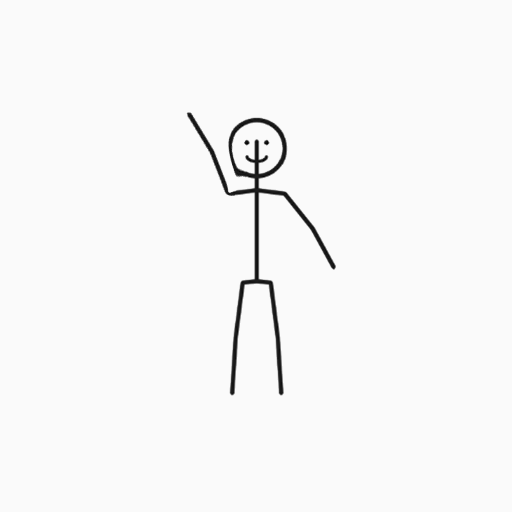

In [ ]:
!MPLBACKEND=Agg python /content/animate_drawing.py --demo --out /content/anim_demo
from IPython.display import Image, display
display(Image('/content/anim_demo/demo.gif'))

## 4. test set 랜덤 그림 움직이기 (GT bbox)
`--from-test` 개수, `--seed`로 다른 그림 뽑기, `--motions wave,dance,walk` 중 골라서 사용.

`/content/test_coco.json`, `/content/data_small/`이 없으면(세션 초기화) 5번을 쓰세요.

In [ ]:
!rm -rf /content/anim_out
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/animate_drawing.py --from-test 6 --seed 0

import glob
from IPython.display import Image, display
for p in sorted(glob.glob('/content/anim_out/*.gif')):
    print(p); display(Image(p))

Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
Traceback (most recent call last):
  File "/content/animate_drawing.py", line 401, in <module>
    main()
  File "/content/animate_drawing.py", line 361, in main
    coco = json.load(open('/content/test_coco.json'))
FileNotFoundError: [Errno 2] No such file or directory: '/content/test_coco.json'
ERROR conda.cli.main_run:execute(148): `conda run python -u /content/animate_drawing.py --from-test 6 --seed 0` failed. (See above for error)
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
Traceback (most recent call last):
  File "/content/animate_drawing.py", line 401, in <module>
    main()
  File "/content/animate_drawing.py", line 361, in main
    coco = json.load(open('/content/test_coco.json'))
FileNotFoundError: [Errno 2] No such file or directory: '/content/test_coco.json'
ERROR conda.cli.main_run:execute(1

## 4-2. 다양한 포즈
- 동작 6종: `wave, dance, walk, cheer, jump, kick, squat` (`--motions jump,kick,squat`처럼 골라서)
- **포즈 따라 하기**: 다른 그림의 자세로 변했다가 돌아옴
  - `--pose-from-test K`: test set의 다른 그림 K개 자세 (GT 관절)
  - `--pose-img 폴더/파일`: 이 이미지의 모델 예측 자세

In [ ]:
!rm -rf /content/anim_pose
# (a) 동작 여러 개
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/animate_drawing.py --from-test 3 --seed 1 --motions cheer,jump,kick,squat --out /content/anim_pose/motions
# (b) 다른 그림 자세 따라 하기 (동작 없이 포즈만)
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/animate_drawing.py --from-test 3 --seed 1 --motions '' --pose-from-test 4 --out /content/anim_pose/transfer

import glob
from IPython.display import Image, display
for p in sorted(glob.glob('/content/anim_pose/*/*.gif')):
    print(p); display(Image(p))

Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
Traceback (most recent call last):
  File "/content/animate_drawing.py", line 401, in <module>
    main()
  File "/content/animate_drawing.py", line 361, in main
    coco = json.load(open('/content/test_coco.json'))
FileNotFoundError: [Errno 2] No such file or directory: '/content/test_coco.json'
ERROR conda.cli.main_run:execute(148): `conda run python -u /content/animate_drawing.py --from-test 3 --seed 1 --motions cheer,jump,kick,squat --out /content/anim_pose/motions` failed. (See above for error)
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
Traceback (most recent call last):
  File "/content/animate_drawing.py", line 401, in <module>
    main()
  File "/content/animate_drawing.py", line 361, in main
    coco = json.load(open('/content/test_coco.json'))
FileNotFoundError: [Errno 2] No such file or direct

## 5. 내 그림 업로드해서 움직이기
bbox를 안 주면 이미지 전체를 사람 영역으로 봄 → 그림이 화면을 꽉 채우는 게 좋음.

In [ ]:
import os, shutil, glob
from google.colab import files
shutil.rmtree('/content/my_imgs', ignore_errors=True); os.makedirs('/content/my_imgs')
up = files.upload()
for n in up: shutil.move(n, f'/content/my_imgs/{n}')

!rm -rf /content/anim_my
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/animate_drawing.py --src /content/my_imgs --out /content/anim_my

from IPython.display import Image, display
for p in sorted(glob.glob('/content/anim_my/*.gif')):
    print(p); display(Image(p))

Saving 782-139519755_medium.mp4 to 782-139519755_medium.mp4
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth


Saving 168502-839220724.mp4 to 168502-839220724.mp4
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth


## 5-2. 영상 속 동작을 그림에 입히기 (데이터 기반)
춤/운동 영상(mp4)을 올리면 → 사전학습 RTMPose로 프레임별 관절을 뽑아 → 그림의 뼈대에 그대로 적용.
- 영상에는 **사람 한 명이 전신**이 나오는 게 좋음 (정면·고정 카메라 권장). 좌우가 바뀌어 보이면 `--mirror`.
- `--save-seq`로 뽑은 관절 시퀀스(.npy)를 저장해두면 영상 없이 재사용 가능 (`--seq`). 모캡(BVH)을 2D로 투영한 (T,15,2) 배열도 같은 방식으로 넣을 수 있음.
- 전제: `/content/rtmpose-m_coco-256x192.pth`와 COCO config가 있어야 함 (원본 학습 노트북 7번 셀 / 환경 복원 후 `wget`).

1) 동작 영상 업로드


Saving 20261014_122510_eb38bd78b5cb9620cf3b6a6bd2f5c258.mp4 to 20261014_122510_eb38bd78b5cb9620cf3b6a6bd2f5c258.mp4
2) 움직일 그림 업로드


Saving 7.png to 7.png
Saving 4.png to 4.png
Saving 3.png to 3.png
Loads checkpoint by local backend from path: /content/rtmpose-m_coco-256x192.pth
video seq (122, 15, 2) fps 12.0
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
3: mean score 0.49 -> -
4: mean score 0.65 -> -
7: mean score 0.53 -> -
/content/anim_video/3_video.gif


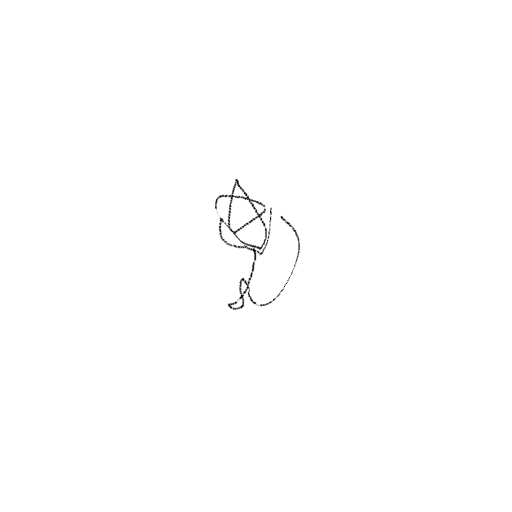

/content/anim_video/4_video.gif


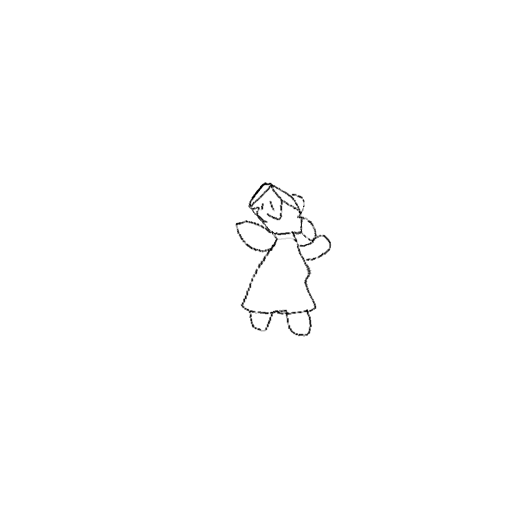

/content/anim_video/7_video.gif


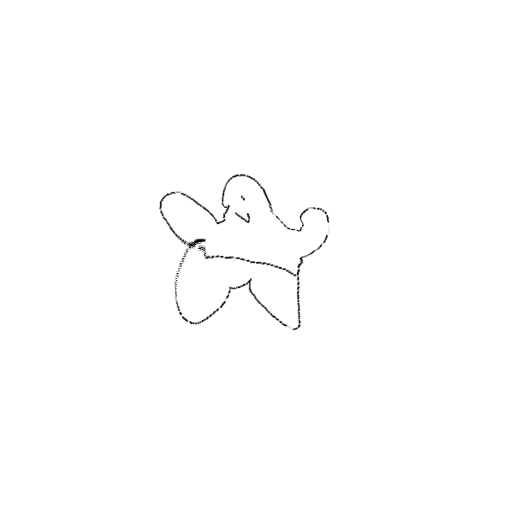

In [ ]:
import os, shutil, glob
from google.colab import files
!test -f /content/rtmpose-m_coco-256x192.pth || wget -q https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/rtmpose-m_simcc-coco_pt-aic-coco_420e-256x192-d8dd5ca4_20230127.pth -O /content/rtmpose-m_coco-256x192.pth

print('1) 동작 영상 업로드')
v = files.upload(); VIDEO = '/content/' + list(v)[0]; os.rename(list(v)[0], VIDEO)
print('2) 움직일 그림 업로드')
shutil.rmtree('/content/my_imgs', ignore_errors=True); os.makedirs('/content/my_imgs')
up = files.upload()
for n in up: shutil.move(n, f'/content/my_imgs/{n}')

!rm -rf /content/anim_video
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/animate_drawing.py --src /content/my_imgs --video {VIDEO} --motions '' \
  --save-seq /content/seq.npy --out /content/anim_video

from IPython.display import Image, display
for p in sorted(glob.glob('/content/anim_video/*_video.gif')):
    print(p); display(Image(p))

## 6. 결과 내려받기

In [ ]:
!cd /content && zip -qr anim_results.zip anim_out anim_my 2>/dev/null; ls -la /content/anim_results.zip
from google.colab import files
files.download('/content/anim_results.zip')

-rw-r--r-- 1 root root 312 Oct 14 12:01 /content/anim_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>